# Anatomy Analysis

This notebook is being built from the requested analysis checklist. The first section chooses one experiment from the app database and loads its shared context for the downstream anatomy-focused analyses.

In [22]:
import importlib
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import tifffile
from sklearn.decomposition import FastICA, PCA

import pandas as pd

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "notebooks" and (NOTEBOOK_DIR / "notebooks").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "notebooks"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import db_notebook_utils as dbu
importlib.reload(dbu)
from db_notebook_utils import available_experiments, load_confirmed_data, load_single_experiment_context
from utils.movie_utils import spatial_bin_movie

In [23]:
# Generate the following analysis:
# 1. choosing a single experiment from the DB
# 2. PCA/ICA on the pb corrected astro movie and plotting the results
# 3. Clicky (manual ROI selection) of regions in the pb corrected astrocyte movie 
# 4. all-neuron spiking raster plot (not just confirmed neurons), sorted by amount of found clusters and with a separating horizontal line between neurons with and without significant clusters
# 5. Amount of confirmed neurons with significant clusters in the "all" configuration vs. the "anatomy" configuration
# 6. Plot of distances of clusters from confirmed neurons both for "all" and "anatomy" configurations
# 7. Commoness heatmap of cluster pixels across all confirmed neurons

## 1. Choose A Single Experiment From The DB

In [41]:
# Use "auto" to pick the first experiment with confirmed cells.
# Or set this to one canonical_id string / experiment_id integer from the displayed table.
SINGLE_EXPERIMENT = "Hyp7__X__15-06-2026_ans__FOV1__z-96__x2"

experiments_df = available_experiments()
display(experiments_df)

single_choice = SINGLE_EXPERIMENT
if single_choice == "auto":
    available_single = experiments_df[experiments_df["n_confirmed_cells"].astype(int) > 0].copy()
    if available_single.empty:
        raise ValueError("No experiments with confirmed cells are available in the database.")
    single_choice = available_single.iloc[0]["canonical_id"]

single_data = load_confirmed_data(single_choice, latest_only=False)
ctx = load_single_experiment_context(single_data)

selected_experiment = pd.DataFrame([
    {
        "experiment_id": ctx.experiment_id,
        "canonical_id": ctx.canonical_id,
        "source_path": str(ctx.source_path),
        "fps": ctx.fps,
        "image_height": ctx.image_shape[0],
        "image_width": ctx.image_shape[1],
        "n_confirmed_cells": len(single_data.cells),
        "n_cluster_rows": len(single_data.clusters),
    }
])
display(selected_experiment)
print(f"Selected {ctx.canonical_id} (experiment_id={ctx.experiment_id}).")

,experiment_id,canonical_id,source_path,recording_date,n_confirmed_cells
0,1,Hyp3__L__02-02-2026_awake__FOV1__z-18__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,02-02-2026,23
1,6,Hyp8__R__12-08-2026_ans__FOV1__z-120__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,12-08-2026,40
2,8,Hyp8__R__12-08-2026_ans__FOV2__z-43__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,12-08-2026,2
3,9,Hyp8__X__12-08-2026_ans__FOV1__z-116__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,12-08-2026,19
4,5,Hyp7__X__15-06-2026_ans__FOV1__z-96__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,15-06-2026,19
5,2,Hyp6__R__25-05-2026_awake__FOV2__z-30__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,25-05-2026,16
6,4,Hyp6__R__27-04-2026_awake__FOV1__z-110__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,27-04-2026,42
7,3,Hyp3__L__30-12-2025_awake__FOV1__z-25__x4,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,30-12-2025,5


,experiment_id,canonical_id,source_path,fps,image_height,image_width,n_confirmed_cells,n_cluster_rows
0,5,Hyp7__X__15-06-2026_ans__FOV1__z-96__x2,Z:\Adam-Lab-Shared\Data\Miki_Meerson\Imaging\H...,29.0,512,512,19,3451


Selected Hyp7__X__15-06-2026_ans__FOV1__z-96__x2 (experiment_id=5).


## 2. PCA/ICA On The PB-Corrected Astro Movie

Loaded 1800/9000 frames from astro_photobleaching_corrected.tif; binned movie shape=(1800, 64, 64), valid pixels=4096.


,component,pca_explained_variance_ratio,pca_cumulative_variance_ratio
0,1,0.013678,0.013678
1,2,0.003356,0.017034
2,3,0.002870,0.019905
3,4,0.002328,0.022232


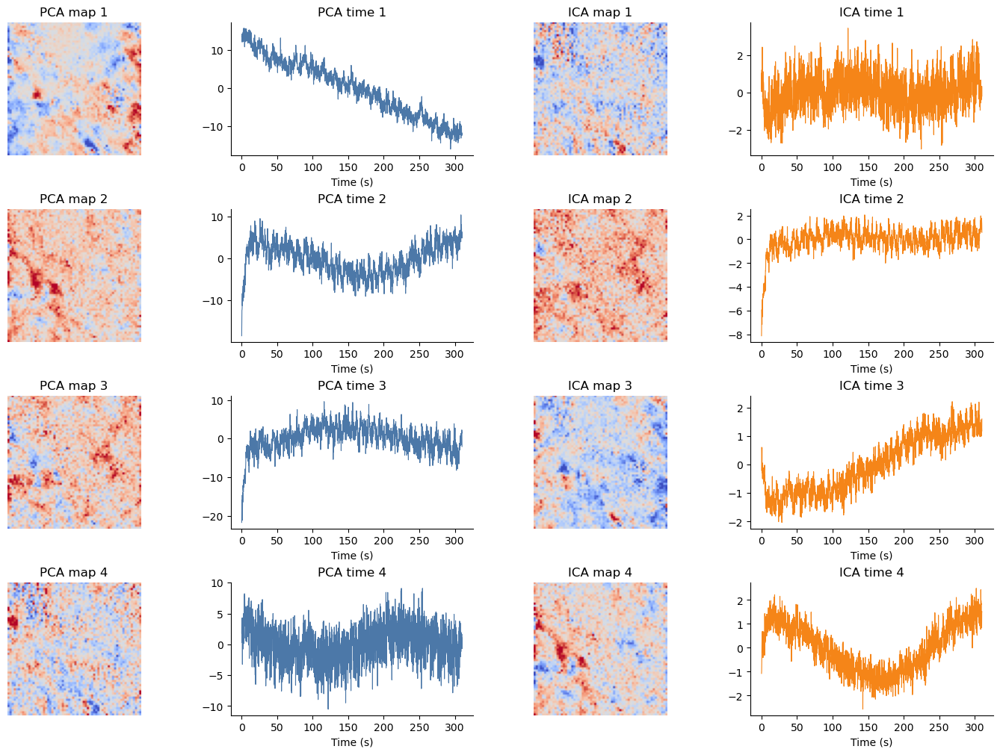

In [42]:
N_COMPONENTS = 4
SPATIAL_BIN = 8
TEMPORAL_STRIDE = 5
MAX_FRAMES = 2500
RANDOM_STATE = 0

astro_movie_path = Path(ctx.paths.astro_movie_path)
if not astro_movie_path.exists():
    raise FileNotFoundError(f"PB-corrected astro movie not found: {astro_movie_path}")

with tifffile.TiffFile(astro_movie_path) as tif:
    series = tif.series[0]
    n_total_frames = int(series.shape[0])
    frame_indices = np.arange(0, n_total_frames, TEMPORAL_STRIDE, dtype=np.int64)
    if frame_indices.size > MAX_FRAMES:
        frame_indices = np.linspace(0, n_total_frames - 1, MAX_FRAMES, dtype=np.int64)
    astro_movie = series.asarray(key=frame_indices)

# Astro GEVI is negatively-going; flip polarity here without loading the full TIFF at once.
astro_movie = -np.asarray(astro_movie, dtype=np.float32)
astro_movie_binned = spatial_bin_movie(astro_movie, SPATIAL_BIN)
del astro_movie

n_frames, n_rows, n_cols = astro_movie_binned.shape
X = astro_movie_binned.reshape(n_frames, -1)
pixel_mean = X.mean(axis=0, keepdims=True)
pixel_std = X.std(axis=0, keepdims=True)
valid_pixels = np.isfinite(pixel_std.ravel()) & (pixel_std.ravel() > 0)
X_valid = (X[:, valid_pixels] - pixel_mean[:, valid_pixels]) / pixel_std[:, valid_pixels]

n_components = min(N_COMPONENTS, X_valid.shape[0], X_valid.shape[1])
if n_components < 1:
    raise ValueError("No valid pixels/frames are available for PCA/ICA.")

pca = PCA(n_components=n_components, svd_solver="randomized", random_state=RANDOM_STATE)
pca_scores = pca.fit_transform(X_valid)

ica = FastICA(n_components=n_components, random_state=RANDOM_STATE, whiten="unit-variance", max_iter=1000, tol=1e-4)
ica_scores = ica.fit_transform(pca_scores)

pca_maps = np.full((n_components, X.shape[1]), np.nan, dtype=np.float32)
pca_maps[:, valid_pixels] = pca.components_.astype(np.float32)
pca_maps = pca_maps.reshape(n_components, n_rows, n_cols)

ica_maps = np.full((n_components, X.shape[1]), np.nan, dtype=np.float32)
ica_maps[:, valid_pixels] = (ica.components_ @ pca.components_).astype(np.float32)
ica_maps = ica_maps.reshape(n_components, n_rows, n_cols)

time_s = frame_indices[:n_frames] / float(ctx.fps)
print(
    f"Loaded {n_frames}/{n_total_frames} frames from {astro_movie_path.name}; "
    f"binned movie shape={astro_movie_binned.shape}, valid pixels={int(valid_pixels.sum())}."
)
display(pd.DataFrame({
    "component": np.arange(1, n_components + 1),
    "pca_explained_variance_ratio": pca.explained_variance_ratio_,
    "pca_cumulative_variance_ratio": np.cumsum(pca.explained_variance_ratio_),
}))

fig, axes = plt.subplots(n_components, 4, figsize=(14, 2.5 * n_components), constrained_layout=True)
if n_components == 1:
    axes = axes[None, :]
for i in range(n_components):
    pca_lim = np.nanpercentile(np.abs(pca_maps[i]), 99)
    ica_lim = np.nanpercentile(np.abs(ica_maps[i]), 99)
    axes[i, 0].imshow(pca_maps[i], cmap="coolwarm", vmin=-pca_lim, vmax=pca_lim)
    axes[i, 0].set_title(f"PCA map {i + 1}")
    axes[i, 1].plot(time_s, pca_scores[:, i], linewidth=0.8, color="#4C78A8")
    axes[i, 1].set_title(f"PCA time {i + 1}")
    axes[i, 2].imshow(ica_maps[i], cmap="coolwarm", vmin=-ica_lim, vmax=ica_lim)
    axes[i, 2].set_title(f"ICA map {i + 1}")
    axes[i, 3].plot(time_s, ica_scores[:, i], linewidth=0.8, color="#F58518")
    axes[i, 3].set_title(f"ICA time {i + 1}")
    for ax in (axes[i, 0], axes[i, 2]):
        ax.set_axis_off()
    for ax in (axes[i, 1], axes[i, 3]):
        ax.set_xlabel("Time (s)")
        ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. All-Neuron Spike Raster Sorted By Cluster Count

,cell_id,n_spikes,n_clusters_for_sort,n_significant_clusters_for_split,n_all_clusters,n_anatomy_clusters,n_all_significant_clusters,n_anatomy_significant_clusters,peak_source
0,89,11,52,1,51,1,1,0,edited_runtime
1,198,18,51,1,49,2,1,0,edited_runtime
2,196,13,47,1,44,3,0,1,edited_runtime
3,34,10,46,2,45,1,1,1,edited_runtime
4,16,19,45,2,42,3,1,1,edited_runtime
5,73,11,45,1,45,0,1,0,edited_runtime
6,103,10,45,1,40,5,0,1,edited_runtime
7,57,24,44,2,43,1,1,1,edited_runtime
8,195,20,44,1,42,2,1,0,edited_runtime
9,4,16,42,1,39,3,1,0,edited_runtime


,peak_source,n_cells
0,edited_runtime,269
1,runtime_spike_run,3


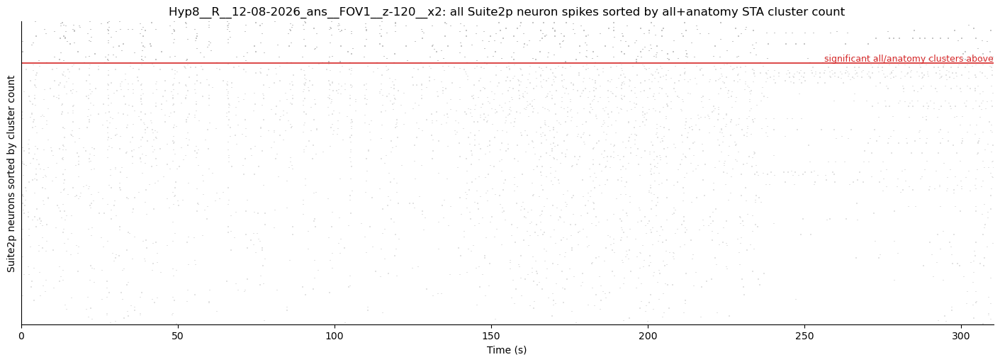

In [26]:
from app.settings import load_settings
from app.db.core import connect

# Include anatomical STA clusters together with the standard all-spike clusters.
CLUSTER_RESULT_TYPES_FOR_RASTER = ["all", "anatomy"]

settings = load_settings()
with connect(settings) as conn:
    spike_run = conn.execute(
        """
        SELECT * FROM analysis_runs
        WHERE experiment_id=? AND step='spike' AND status='completed' AND is_test=0
        ORDER BY id DESC
        LIMIT 1
        """,
        (ctx.experiment_id,),
    ).fetchone()
if spike_run is None or not spike_run["output_dir"]:
    raise FileNotFoundError(f"No completed app spike run found for {ctx.canonical_id}. Run spike detection first.")

spike_output_dir = Path(spike_run["output_dir"])
if not spike_output_dir.exists():
    raise FileNotFoundError(f"Latest app spike output directory does not exist: {spike_output_dir}")

def load_edited_spikes_for_cell(cell_id):
    path = spike_output_dir / f"cell_{int(cell_id)}" / "simple_complex_spike_labels.npz"
    if not path.exists():
        return np.asarray([], dtype=np.int32), "missing_runtime_spike_file"
    with np.load(path, allow_pickle=True) as d:
        peaks = np.asarray(d["peaks_all"], dtype=np.int32) if "peaks_all" in d else np.asarray([], dtype=np.int32)
        labels = np.asarray(d["labels"]).astype(str) if "labels" in d else np.full(peaks.shape, "simple")
    order = np.argsort(peaks)
    peaks = peaks[order]
    labels = np.char.lower(labels[order].astype("U16"))
    peaks = peaks[labels != "exclude"]
    source = "edited_runtime" if (path.parent / "manual_spike_review.json").exists() else "runtime_spike_run"
    return np.sort(peaks), source

cluster_source = single_data.clusters.copy()
if cluster_source.empty:
    cluster_source = pd.DataFrame(columns=["cell_id", "cluster_id", "result_type", "is_significant"])
else:
    cluster_source = cluster_source[cluster_source["result_type"].isin(CLUSTER_RESULT_TYPES_FOR_RASTER)].copy()
    cluster_source["cell_id"] = cluster_source["cell_id"].astype(int)
    cluster_source["cluster_id"] = cluster_source["cluster_id"].astype(int)
    cluster_source["is_significant"] = cluster_source["is_significant"].astype(bool)

cluster_count_by_type = {}
sig_count_by_type = {}
for result_type in CLUSTER_RESULT_TYPES_FOR_RASTER:
    by_type = cluster_source[cluster_source["result_type"].eq(result_type)]
    if by_type.empty:
        cluster_count_by_type[result_type] = pd.Series(dtype=int)
        sig_count_by_type[result_type] = pd.Series(dtype=int)
    else:
        cluster_count_by_type[result_type] = by_type.groupby("cell_id")["cluster_id"].nunique().astype(int)
        sig_count_by_type[result_type] = by_type[by_type["is_significant"]].groupby("cell_id")["cluster_id"].nunique().astype(int)

raster_rows = []
for cell_id in range(int(ctx.suite2p_ctx["n_cells"])):
    peaks, peak_source = load_edited_spikes_for_cell(cell_id)
    row = {
        "cell_id": int(cell_id),
        "all_peaks": peaks,
        "n_spikes": int(peaks.size),
        "peak_source": peak_source,
    }
    for result_type in CLUSTER_RESULT_TYPES_FOR_RASTER:
        row[f"n_{result_type}_clusters"] = int(cluster_count_by_type[result_type].get(cell_id, 0))
        row[f"n_{result_type}_significant_clusters"] = int(sig_count_by_type[result_type].get(cell_id, 0))
    raster_rows.append(row)

all_neuron_raster_df = pd.DataFrame(raster_rows)
cluster_cols = [f"n_{result_type}_clusters" for result_type in CLUSTER_RESULT_TYPES_FOR_RASTER]
sig_cols = [f"n_{result_type}_significant_clusters" for result_type in CLUSTER_RESULT_TYPES_FOR_RASTER]
all_neuron_raster_df["n_clusters_for_sort"] = all_neuron_raster_df[cluster_cols].sum(axis=1)
all_neuron_raster_df["n_significant_clusters_for_split"] = all_neuron_raster_df[sig_cols].sum(axis=1)
all_neuron_raster_df["has_significant_cluster"] = all_neuron_raster_df["n_significant_clusters_for_split"] > 0

raster_df = all_neuron_raster_df.sort_values(
    ["has_significant_cluster", "n_clusters_for_sort", "n_spikes", "cell_id"],
    ascending=[False, False, False, True],
).reset_index(drop=True)

display(raster_df[["cell_id", "n_spikes", "n_clusters_for_sort", "n_significant_clusters_for_split", *cluster_cols, *sig_cols, "peak_source"]].head(25))
display(raster_df["peak_source"].value_counts().rename_axis("peak_source").reset_index(name="n_cells"))

max_peak = max((int(peaks.max()) for peaks in raster_df["all_peaks"] if peaks.size), default=0)
split_idx = int(raster_df["has_significant_cluster"].sum())

fig_height = max(5, min(5, 0.08 * len(raster_df) + 1.5))
fig, ax = plt.subplots(figsize=(14, fig_height), constrained_layout=True)
for y, row in enumerate(raster_df.itertuples()):
    peaks = np.asarray(row.all_peaks, dtype=np.int32)
    color = "#111111" if row.has_significant_cluster else "#8A8A8A"
    if peaks.size:
        ax.vlines(peaks / float(ctx.fps), y - 0.42, y + 0.42, color=color, linewidth=0.35)

if 0 < split_idx < len(raster_df):
    ax.axhline(split_idx - 0.5, color="#D62728", linewidth=1.2)
    ax.text(
        max_peak / float(ctx.fps),
        split_idx - 0.65,
        "significant all/anatomy clusters above",
        color="#D62728",
        ha="right",
        va="bottom",
        fontsize=9,
    )

ax.set_title(f"{ctx.canonical_id}: all Suite2p neuron spikes sorted by all+anatomy STA cluster count")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Suite2p neurons sorted by cluster count")
ax.set_xlim(0, max(1, max_peak / float(ctx.fps)))
ax.set_ylim(len(raster_df) - 0.5, -0.5)
ax.set_yticks([])
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4b. Two-Second Spike-Count Correlation Matrix

,bin_seconds,bin_frames,n_bins,n_cells,n_cells_with_nonzero_variance,n_cells_with_significant_all_or_anatomy_clusters
0,5,145,63,272,272,38


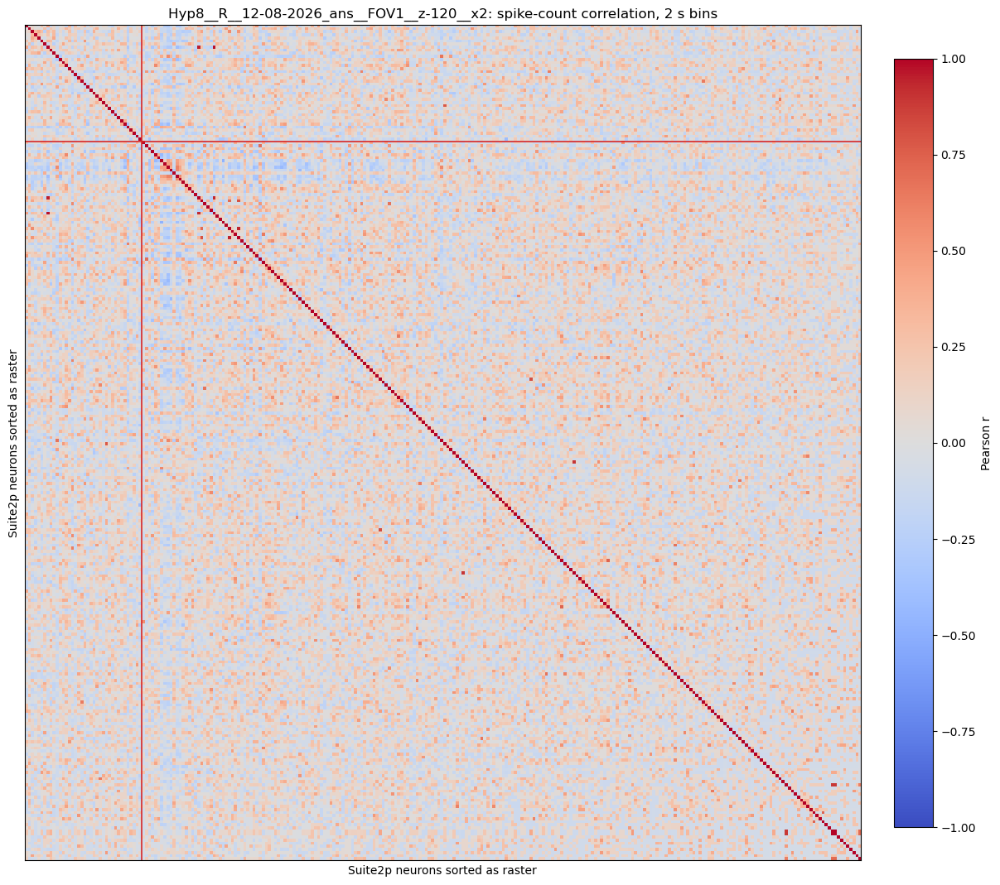

In [27]:
CORRELATION_BIN_SECONDS = 5

if "raster_df" not in globals():
    raise NameError("Run the all-neuron raster cell first so raster_df contains the sorted neuron order.")

bin_frames = max(1, int(round(CORRELATION_BIN_SECONDS * float(ctx.fps))))
max_peak = max((int(peaks.max()) for peaks in raster_df["all_peaks"] if peaks.size), default=0)
n_bins = max(1, int(np.ceil((max_peak + 1) / bin_frames)))

cell_ids = raster_df["cell_id"].to_numpy(dtype=int)
spike_counts_2s = np.zeros((len(raster_df), n_bins), dtype=np.float32)
for row_idx, peaks in enumerate(raster_df["all_peaks"]):
    peaks = np.asarray(peaks, dtype=np.int32)
    bins = np.floor_divide(peaks, bin_frames)
    bins = bins[(bins >= 0) & (bins < n_bins)]
    if bins.size:
        spike_counts_2s[row_idx] = np.bincount(bins, minlength=n_bins).astype(np.float32)

valid_for_corr = spike_counts_2s.std(axis=1) > 0
correlation_matrix_2s = np.full((len(raster_df), len(raster_df)), np.nan, dtype=np.float32)
if valid_for_corr.sum() >= 2:
    corr_valid = np.corrcoef(spike_counts_2s[valid_for_corr])
    valid_idx = np.flatnonzero(valid_for_corr)
    correlation_matrix_2s[np.ix_(valid_idx, valid_idx)] = corr_valid.astype(np.float32)
elif valid_for_corr.sum() == 1:
    idx = int(np.flatnonzero(valid_for_corr)[0])
    correlation_matrix_2s[idx, idx] = 1.0

split_idx = int(raster_df["has_significant_cluster"].sum())
summary = pd.DataFrame([
    {
        "bin_seconds": CORRELATION_BIN_SECONDS,
        "bin_frames": bin_frames,
        "n_bins": n_bins,
        "n_cells": len(raster_df),
        "n_cells_with_nonzero_variance": int(valid_for_corr.sum()),
        "n_cells_with_significant_all_or_anatomy_clusters": split_idx,
    }
])
display(summary)

fig_size = max(6, min(12, 0.035 * len(raster_df) + 4))
fig, ax = plt.subplots(figsize=(fig_size, fig_size), constrained_layout=True)
im = ax.imshow(correlation_matrix_2s, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
if 0 < split_idx < len(raster_df):
    ax.axhline(split_idx - 0.5, color="#D62728", linewidth=1.2)
    ax.axvline(split_idx - 0.5, color="#D62728", linewidth=1.2)
ax.set_title(f"{ctx.canonical_id}: spike-count correlation, 2 s bins")
ax.set_xlabel("Suite2p neurons sorted as raster")
ax.set_ylabel("Suite2p neurons sorted as raster")
ax.set_xticks([])
ax.set_yticks([])
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson r")
plt.show()

## 5. Confirmed Neuron Traces With Spike Frames

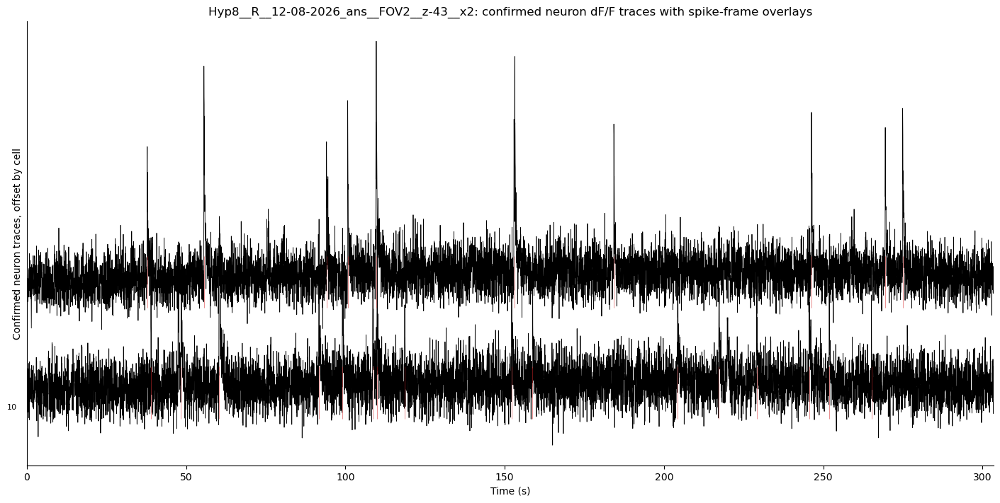

,cell_id,n_spikes,n_sig_clusters
0,10,16,1
1,3,10,1


In [35]:
def robust_dff(trace, baseline_percentile=8):
    y = np.asarray(trace, dtype=float).ravel()
    if y.size == 0:
        return y
    f0 = float(np.nanpercentile(y, baseline_percentile))
    if not np.isfinite(f0):
        return y
    return (y - f0) / (abs(f0) + 1e-6)

confirmed_peaks_df = single_data.peaks.copy()
if confirmed_peaks_df.empty:
    raise ValueError("No confirmed neurons with peak rows are available for the selected experiment.")

confirmed_sig_counts = (
    single_data.clusters[single_data.clusters["is_significant"]]
    .groupby("cell_id")["cluster_id"]
    .nunique()
    .astype(int)
)
confirmed_peaks_df["n_sig_clusters"] = confirmed_peaks_df["cell_id"].map(confirmed_sig_counts).fillna(0).astype(int)
confirmed_peaks_df = confirmed_peaks_df.sort_values(["n_sig_clusters", "n_all_peaks", "cell_id"], ascending=[False, False, True]).reset_index(drop=True)

F = np.asarray(ctx.suite2p_ctx["F"], dtype=np.float32)
trace_time_s = np.arange(F.shape[1], dtype=np.float32) / float(ctx.fps)

fig, ax = plt.subplots(figsize=(14, max(7, 0.45 * len(confirmed_peaks_df))), constrained_layout=True)
offset = 0.0
trace_summary_rows = []
for row in confirmed_peaks_df.itertuples():
    cell_id = int(row.cell_id)
    if cell_id >= F.shape[0]:
        continue
    trace = robust_dff(F[cell_id])
    finite = trace[np.isfinite(trace)]
    if finite.size:
        local_span = max(float(np.nanpercentile(finite, 99) - np.nanpercentile(finite, 1)), 0.2)
    else:
        local_span = 1.0
    trace_scaled = trace / local_span
    ax.plot(trace_time_s, trace_scaled + offset, color="black", linewidth=0.6)
    peaks = np.asarray(row.all_peaks, dtype=np.int32)
    peaks = peaks[(peaks >= 0) & (peaks < F.shape[1])]
    if peaks.size:
        ax.vlines(peaks / float(ctx.fps), offset - 0.12, offset + 0.42, color="#D62728", linewidth=0.45, alpha=0.8)
    ax.text(-0.01 * trace_time_s[-1], offset, str(cell_id), ha="right", va="center", fontsize=8)
    trace_summary_rows.append({"cell_id": cell_id, "n_spikes": int(peaks.size), "n_sig_clusters": int(row.n_sig_clusters)})
    offset += 1.15

ax.set_title(f"{ctx.canonical_id}: confirmed neuron dF/F traces with spike-frame overlays")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Confirmed neuron traces, offset by cell")
ax.set_xlim(0, float(trace_time_s[-1]) if trace_time_s.size else 1)
ax.set_yticks([])
ax.spines[["top", "right"]].set_visible(False)
plt.show()
display(pd.DataFrame(trace_summary_rows).head(25))

## 6. Confirmed Neuron Cluster Outlines And Cluster Traces

,anatomy_crop_params_path,anatomy_radius_binned,spatial_bin
0,Z:\Adam-Lab-Shared\Code\Miki\astro-analysis-pi...,8,8





Loaded actual cluster ROI traces for 47 clusters from \\ems\adam-lab\Adam-Lab-Shared\Code\Miki\astro-analysis-pipeline\notebooks\.cache\Hyp8__R__12-08-2026_ans__FOV1__z-120__x2_actual_cluster_roi_traces_fullres.npz.


,cell_id,result_type,sign,cluster_id,mean_f0,median_f0,baseline_mean_after_dff,n_pixels,n_spikes
0,4,all,depolarizing,1,-1624.554604,-1615.874878,2.913876e-08,576,16
1,6,all,depolarizing,1,-1878.994320,-1877.397217,-1.472731e-08,576,15
2,6,all,depolarizing,2,-1911.663810,-1927.580688,-7.112200e-09,704,15
3,6,all,depolarizing,3,-1891.521419,-1888.688232,4.659718e-09,576,15
4,14,all,hyperpolarizing,1,-1848.664710,-1850.347046,-6.540750e-09,896,26
5,16,all,hyperpolarizing,1,-1844.047100,-1840.393555,4.587989e-09,896,19
6,16,anatomy,hyperpolarizing,1,-1378.192845,-1369.827393,-6.470241e-10,256,19
7,17,all,hyperpolarizing,1,-1994.498884,-1962.534241,1.702990e-09,1088,14
8,23,anatomy,depolarizing,1,-596.985311,-591.638092,-6.332994e-09,320,6
9,28,anatomy,depolarizing,1,-729.086723,-739.517578,5.867332e-09,256,8





In [31]:
from app.settings import load_settings
from app.db.core import connect
from db_notebook_utils import load_cluster_mask
from utils.suite2p_utils import get_neuron_outline, neuron_centroid_binned
from utils.movie_utils import _reorder_tiff_to_thw

CLUSTER_RESULT_TYPES_TO_PLOT = ["all", "anatomy"]
ONLY_SIGNIFICANT_CLUSTERS = True
MAX_CONFIRMED_CLUSTER_PLOT_CELLS = None  # Set to an integer for a faster preview.

cluster_plot_df = single_data.clusters[single_data.clusters["result_type"].isin(CLUSTER_RESULT_TYPES_TO_PLOT)].copy()
if ONLY_SIGNIFICANT_CLUSTERS:
    cluster_plot_df = cluster_plot_df[cluster_plot_df["is_significant"]].copy()
if cluster_plot_df.empty:
    raise ValueError("No clusters are available for the requested result types/significance filter.")
cluster_plot_df["cell_id"] = cluster_plot_df["cell_id"].astype(int)
cluster_plot_df["cluster_id"] = cluster_plot_df["cluster_id"].astype(int)

polarity_label = {"positive": "depolarizing", "negative": "hyperpolarizing"}
polarity_color = {"positive": "#D62728", "negative": "#1F77B4"}
result_linestyle = {"all": "solid", "anatomy": "dashed"}
result_linewidth = {"all": 1.0, "anatomy": 1.6}
neuron_color = "#F58518"

def _latest_completed_run_output_dir(experiment_id, step):
    settings = load_settings()
    with connect(settings) as conn:
        run = conn.execute(
            """
            SELECT output_dir FROM analysis_runs
            WHERE experiment_id=? AND step=? AND status='completed' AND is_test=0
            ORDER BY id DESC
            LIMIT 1
            """,
            (int(experiment_id), str(step)),
        ).fetchone()
    if run is None or not run["output_dir"]:
        return None
    return Path(run["output_dir"])

def _load_anatomy_crop_settings():
    run_dir = _latest_completed_run_output_dir(ctx.experiment_id, "anatomy")
    candidates = []
    if run_dir is not None:
        candidates.append(run_dir / "sta-analysis" / "anatomy_crop_params.npz")
    candidates.append(Path(ctx.source_path) / "sta-analysis" / "anatomy_crop_params.npz")
    for path in candidates:
        if path.exists():
            with np.load(path, allow_pickle=True) as d:
                radius = int(np.asarray(d["anatomy_radius_binned"]).item())
                spatial_bin = int(np.asarray(d["spatial_bin"]).item()) if "spatial_bin" in d else int(globals().get("SPATIAL_BIN", 8))
            return {"path": path, "radius": radius, "spatial_bin": spatial_bin}
    return {"path": None, "radius": None, "spatial_bin": int(globals().get("SPATIAL_BIN", 8))}

anatomy_crop_settings = _load_anatomy_crop_settings()
display(pd.DataFrame([{
    "anatomy_crop_params_path": str(anatomy_crop_settings["path"]) if anatomy_crop_settings["path"] else "not found; infer from mask size",
    "anatomy_radius_binned": anatomy_crop_settings["radius"],
    "spatial_bin": anatomy_crop_settings["spatial_bin"],
}]))

def _crop_bounds(center_yx, radius, image_shape):
    y, x = center_yx
    height, width = image_shape
    return (
        max(0, int(y) - int(radius)),
        min(height, int(y) + int(radius) + 1),
        max(0, int(x) - int(radius)),
        min(width, int(x) + int(radius) + 1),
    )

def _mask_to_full_fov_binned(row, binned_shape):
    mask = load_cluster_mask(row)
    if mask is None:
        return None
    mask = np.asarray(mask, dtype=bool)
    result_type = str(row["result_type"])
    if result_type == "anatomy":
        radius = anatomy_crop_settings["radius"]
        if radius is None:
            radius = max(mask.shape) // 2
        center = neuron_centroid_binned(int(row["cell_id"]), anatomy_crop_settings["spatial_bin"], binned_shape, ctx.suite2p_ctx)
        y0, y1, x0, x1 = _crop_bounds(center, radius, binned_shape)
        full = np.zeros(binned_shape, dtype=bool)
        h = min(mask.shape[0], y1 - y0)
        w = min(mask.shape[1], x1 - x0)
        full[y0:y0 + h, x0:x0 + w] = mask[:h, :w]
        return full
    if mask.shape == tuple(binned_shape):
        return mask
    if mask.shape == tuple(ctx.image_shape):
        by = max(1, mask.shape[0] // binned_shape[0])
        bx = max(1, mask.shape[1] // binned_shape[1])
        cropped = mask[: binned_shape[0] * by, : binned_shape[1] * bx]
        return cropped.reshape(binned_shape[0], by, binned_shape[1], bx).any(axis=(1, 3))
    if mask.shape[0] <= binned_shape[0] and mask.shape[1] <= binned_shape[1]:
        full = np.zeros(binned_shape, dtype=bool)
        full[:mask.shape[0], :mask.shape[1]] = mask
        return full
    return None

def _upscale_bool_mask(mask, display_shape):
    mask = np.asarray(mask, dtype=bool)
    sy = int(np.ceil(display_shape[0] / mask.shape[0]))
    sx = int(np.ceil(display_shape[1] / mask.shape[1]))
    up = np.kron(mask, np.ones((sy, sx), dtype=bool))
    return up[: display_shape[0], : display_shape[1]]

binned_shape = tuple(np.ceil(np.asarray(ctx.image_shape) / anatomy_crop_settings["spatial_bin"]).astype(int))
if "confirmed_peaks_df" not in globals():
    confirmed_peaks_df = single_data.peaks.copy()
    sig_counts = cluster_plot_df.groupby("cell_id")["cluster_id"].nunique().astype(int)
    confirmed_peaks_df["n_sig_clusters"] = confirmed_peaks_df["cell_id"].map(sig_counts).fillna(0).astype(int)
    confirmed_peaks_df = confirmed_peaks_df.sort_values(["n_sig_clusters", "n_all_peaks", "cell_id"], ascending=[False, False, True]).reset_index(drop=True)
confirmed_cell_ids = confirmed_peaks_df["cell_id"].to_numpy(dtype=int)
if MAX_CONFIRMED_CLUSTER_PLOT_CELLS is not None:
    confirmed_cell_ids = confirmed_cell_ids[: int(MAX_CONFIRMED_CLUSTER_PLOT_CELLS)]

astro_values = []
for t in cluster_plot_df["mean_trace"]:
    arr = np.asarray(t, dtype=float)
    if arr.size:
        astro_values.append(arr[np.isfinite(arr)])
astro_radius = max(float(np.nanmax(np.abs(np.concatenate(astro_values)))), 1e-6) * 1.08 if astro_values else 1.0

fig = plt.figure(figsize=(15, max(5, 3.0 * len(confirmed_cell_ids))), constrained_layout=True)
gs = fig.add_gridspec(len(confirmed_cell_ids), 2, width_ratios=[1.0, 1.35])

for row_idx, cell_id in enumerate(confirmed_cell_ids):
    rows = cluster_plot_df[cluster_plot_df["cell_id"].eq(int(cell_id))].copy()
    ax_img = fig.add_subplot(gs[row_idx, 0])
    ax_trace = fig.add_subplot(gs[row_idx, 1])

    ax_img.imshow(ctx.astro_mean_img, cmap="gray")
    roi_mask = get_neuron_outline(int(cell_id), ctx.paths.suite2p_path, ctx.image_shape, spatial_bin=1).astype(bool)
    if roi_mask.any():
        ax_img.contour(roi_mask.astype(float), levels=[0.5], colors=[neuron_color], linewidths=1.0, alpha=0.95)

    display_masks = []
    for _, cluster_row in rows.sort_values(["result_type", "sign", "cluster_id"]).iterrows():
        binned_mask = _mask_to_full_fov_binned(cluster_row, binned_shape)
        if binned_mask is None or not binned_mask.any():
            continue
        display_masks.append((cluster_row, _upscale_bool_mask(binned_mask, ctx.image_shape)))
    for cluster_row, mask in display_masks:
        sign_key = str(cluster_row["sign"]).lower()
        result_type = str(cluster_row["result_type"])
        ax_img.contour(
            mask.astype(float),
            levels=[0.5],
            colors=[polarity_color.get(sign_key, "0.4")],
            linewidths=result_linewidth.get(result_type, 1.0),
            linestyles=result_linestyle.get(result_type, "solid"),
            alpha=0.95,
        )
    ax_img.set_title(f"Cell {cell_id}: mean astro + all/anatomy clusters")
    ax_img.set_axis_off()

    if rows.empty:
        ax_trace.text(0.5, 0.5, "no clusters", transform=ax_trace.transAxes, ha="center", va="center")
        ax_trace.set_axis_off()
        continue
    traces_by_group = {}
    for cluster_row in rows.sort_values(["result_type", "sign", "cluster_id"]).itertuples():
        y = np.asarray(cluster_row.mean_trace, dtype=float)
        t_rel = np.asarray(cluster_row.t_rel, dtype=int)
        if y.size == 0 or y.size != t_rel.size:
            continue
        x_ms = t_rel.astype(np.float32) * (1000.0 / float(ctx.fps))
        result_type = str(cluster_row.result_type)
        sign_key = str(cluster_row.sign).lower()
        color = polarity_color.get(sign_key, "0.4")
        linestyle = result_linestyle.get(result_type, "solid")
        ax_trace.plot(x_ms, y, color=color, linestyle=linestyle, linewidth=0.8, alpha=0.28)
        traces_by_group.setdefault((result_type, sign_key, tuple(t_rel.tolist())), []).append(y)
    for (result_type, sign_key, t_rel_tuple), traces in traces_by_group.items():
        if not traces:
            continue
        arr = np.vstack(traces)
        x_ms = np.asarray(t_rel_tuple, dtype=np.float32) * (1000.0 / float(ctx.fps))
        label = f"{result_type} {polarity_label.get(sign_key, sign_key)} (n={arr.shape[0]})"
        ax_trace.plot(
            x_ms,
            np.nanmean(arr, axis=0),
            color=polarity_color.get(sign_key, "0.4"),
            linestyle=result_linestyle.get(result_type, "solid"),
            linewidth=2.4,
            label=label,
        )
    ax_trace.axvline(0, color="0.55", linewidth=1)
    ax_trace.axhline(0, color="0.82", linewidth=1)
    ax_trace.set_ylim(-0.15, 0.15)
    ax_trace.set_title(f"Cell {cell_id}: cluster STA effect traces")
    ax_trace.set_xlabel("Time from spike (ms)")
    ax_trace.set_ylabel("Cluster STA effect (baseline-subtracted dF/F)")
    ax_trace.spines[["top", "right"]].set_visible(False)
    ax_trace.legend(frameon=False, fontsize=7, ncol=2, loc="best")

fig.suptitle(f"{ctx.canonical_id}: confirmed-neuron cluster outlines and traces (all + anatomy)", y=1.002)
plt.show()

# Actual dF/F traces from the full-resolution PB-corrected astro movie.
# F0 is computed separately for each spike window from the first half of the pre-spike frames.
CLUSTER_DFF_BASELINE_MODE = "first_half_pre_spike_mean"
CLUSTER_DFF_FRAME_CHUNK = 256

def _open_flipped_astro_movie_memmap(movie_path):
    tif = tifffile.TiffFile(movie_path)
    series = tif.series[0]
    axes = getattr(series, "axes", "")
    movie = _reorder_tiff_to_thw(series.asarray(out="memmap"), axes)
    return tif, movie

def _flipped_roi_traces_from_movie(movie, cluster_specs, frame_chunk=256):
    mask_indices = []
    for spec in cluster_specs:
        mask = np.asarray(spec["fullres_mask"], dtype=bool)
        if mask.shape != tuple(movie.shape[1:]):
            raise ValueError(f"Mask shape {mask.shape} does not match movie frame shape {movie.shape[1:]}.")
        mask_indices.append(np.flatnonzero(mask.ravel()))
    traces = np.full((len(cluster_specs), movie.shape[0]), np.nan, dtype=np.float32)
    for start in range(0, movie.shape[0], int(frame_chunk)):
        stop = min(movie.shape[0], start + int(frame_chunk))
        # Flip the negatively-going astro GEVI chunk to app-standard polarity.
        chunk = -np.asarray(movie[start:stop], dtype=np.float32).reshape(stop - start, -1)
        for idx, pix in enumerate(mask_indices):
            if pix.size:
                traces[idx, start:stop] = chunk[:, pix].mean(axis=1)
    return {spec["key"]: traces[idx] for idx, spec in enumerate(cluster_specs)}

def _cluster_actual_dff_sta(cluster_row, roi_trace, fullres_mask):
    roi_trace = np.asarray(roi_trace, dtype=np.float32)
    t_rel = np.asarray(cluster_row["t_rel"], dtype=int)
    pre_idx = np.flatnonzero(t_rel < 0)
    if pre_idx.size:
        baseline_idx = pre_idx[: max(1, int(np.ceil(pre_idx.size / 2.0)))]
    else:
        baseline_idx = np.asarray([], dtype=int)
    if baseline_idx.size == 0:
        baseline_idx = np.asarray([0], dtype=int)
    peak_rows = confirmed_peaks_df[confirmed_peaks_df["cell_id"].eq(int(cluster_row["cell_id"]))]
    if peak_rows.empty:
        return None
    peaks = np.asarray(peak_rows.iloc[0]["all_peaks"], dtype=np.int32)
    peaks = peaks[(peaks >= 0) & (peaks < roi_trace.size)]
    segments = []
    f0_values = []
    for peak in peaks:
        idx = peak + t_rel
        if np.all((idx >= 0) & (idx < roi_trace.size)):
            segment = roi_trace[idx]
            f0 = float(np.nanmean(segment[baseline_idx]))
            if np.isfinite(f0) and abs(f0) > 1e-6:
                segments.append((segment - f0) / abs(f0))
                f0_values.append(f0)
    if not segments:
        return None
    arr = np.vstack(segments)
    baseline_mean = float(np.nanmean(arr[:, baseline_idx])) if baseline_idx.size else np.nan
    return {
        "trace": np.nanmean(arr, axis=0),
        "t_rel": t_rel,
        "f0_t_rel": t_rel[baseline_idx],
        "baseline_idx": baseline_idx,
        "mean_f0": float(np.nanmean(f0_values)),
        "median_f0": float(np.nanmedian(f0_values)),
        "baseline_mean_after_dff": baseline_mean,
        "n_spikes": int(len(segments)),
        "n_pixels": int(np.asarray(fullres_mask, dtype=bool).sum()),
    }

cluster_specs = []
for _, cluster_row in cluster_plot_df.sort_values(["cell_id", "result_type", "sign", "cluster_id"]).iterrows():
    binned_mask = _mask_to_full_fov_binned(cluster_row, binned_shape)
    if binned_mask is None or not binned_mask.any():
        continue
    fullres_mask = _upscale_bool_mask(binned_mask, ctx.image_shape)
    key = (int(cluster_row["cell_id"]), str(cluster_row["result_type"]), str(cluster_row["sign"]).lower(), int(cluster_row["cluster_id"]))
    cluster_specs.append({"key": key, "row": cluster_row, "fullres_mask": fullres_mask})

def _cluster_key_label(key):
    return "__".join(map(str, key))

actual_dff_cache_dir = NOTEBOOK_DIR / ".cache"
actual_dff_cache_dir.mkdir(exist_ok=True)
actual_dff_cache_path = actual_dff_cache_dir / f"{ctx.canonical_id}_actual_cluster_roi_traces_fullres.npz"
cluster_signature = np.asarray([_cluster_key_label(spec["key"]) for spec in cluster_specs], dtype=object)
movie_mtime_ns = int(Path(ctx.paths.astro_movie_path).stat().st_mtime_ns)

roi_traces_by_cluster = None
if actual_dff_cache_path.exists():
    with np.load(actual_dff_cache_path, allow_pickle=True) as cache:
        cache_signature = np.asarray(cache.get("cluster_signature", []), dtype=object)
        cache_mtime = int(np.asarray(cache.get("movie_mtime_ns", -1)).item()) if "movie_mtime_ns" in cache else -1
        if cache_mtime == movie_mtime_ns and np.array_equal(cache_signature, cluster_signature):
            roi_traces_by_cluster = {
                spec["key"]: np.asarray(cache[f"trace_{idx}"], dtype=np.float32)
                for idx, spec in enumerate(cluster_specs)
                if f"trace_{idx}" in cache
            }

if roi_traces_by_cluster is None:
    astro_movie_tif, astro_movie_fullres = _open_flipped_astro_movie_memmap(ctx.paths.astro_movie_path)
    try:
        roi_traces_by_cluster = _flipped_roi_traces_from_movie(astro_movie_fullres, cluster_specs, CLUSTER_DFF_FRAME_CHUNK)
    finally:
        astro_movie_tif.close()
    np.savez_compressed(
        actual_dff_cache_path,
        movie_mtime_ns=np.asarray(movie_mtime_ns, dtype=np.int64),
        cluster_signature=cluster_signature,
        **{f"trace_{idx}": roi_traces_by_cluster[spec["key"]] for idx, spec in enumerate(cluster_specs)},
    )
print(f"Loaded actual cluster ROI traces for {len(cluster_specs)} clusters from {actual_dff_cache_path}.")

actual_dff_by_cluster = {}
actual_dff_rows = []
for spec in cluster_specs:
    key = spec["key"]
    cluster_row = spec["row"]
    roi_trace = roi_traces_by_cluster.get(key)
    if roi_trace is None:
        continue
    sta = _cluster_actual_dff_sta(cluster_row, roi_trace, spec["fullres_mask"])
    if sta is None:
        continue
    actual_dff_by_cluster[key] = sta
    actual_dff_rows.append({
        "cell_id": key[0],
        "result_type": key[1],
        "sign": polarity_label.get(key[2], key[2]),
        "cluster_id": key[3],
        "mean_f0": sta["mean_f0"],
        "median_f0": sta["median_f0"],
        "baseline_mean_after_dff": sta["baseline_mean_after_dff"],
        "n_pixels": sta["n_pixels"],
        "n_spikes": sta["n_spikes"],
    })

fullres_mask_by_cluster = {spec["key"]: spec["fullres_mask"] for spec in cluster_specs}
actual_dff_summary = pd.DataFrame(actual_dff_rows)
display(actual_dff_summary.head(25))

actual_values = [np.asarray(v["trace"], dtype=float) for v in actual_dff_by_cluster.values() if np.asarray(v["trace"]).size]
actual_radius = max(float(np.nanpercentile(np.abs(np.concatenate(actual_values)), 99)), 1e-6) * 1.15 if actual_values else 1.0

fig = plt.figure(figsize=(15, max(5, 3.0 * len(confirmed_cell_ids))), constrained_layout=True)
gs = fig.add_gridspec(len(confirmed_cell_ids), 2, width_ratios=[1.0, 1.35])
for row_idx, cell_id in enumerate(confirmed_cell_ids):
    rows = cluster_plot_df[cluster_plot_df["cell_id"].eq(int(cell_id))].copy()
    ax_img = fig.add_subplot(gs[row_idx, 0])
    ax_trace = fig.add_subplot(gs[row_idx, 1])

    ax_img.imshow(ctx.astro_mean_img, cmap="gray")
    roi_mask = get_neuron_outline(int(cell_id), ctx.paths.suite2p_path, ctx.image_shape, spatial_bin=1).astype(bool)
    if roi_mask.any():
        ax_img.contour(roi_mask.astype(float), levels=[0.5], colors=[neuron_color], linewidths=1.0, alpha=0.95)
    for _, cluster_row in rows.sort_values(["result_type", "sign", "cluster_id"]).iterrows():
        result_type = str(cluster_row["result_type"])
        sign_key = str(cluster_row["sign"]).lower()
        key = (int(cluster_row["cell_id"]), result_type, sign_key, int(cluster_row["cluster_id"]))
        mask = fullres_mask_by_cluster.get(key)
        if mask is None or key not in actual_dff_by_cluster:
            continue
        ax_img.contour(
            np.asarray(mask, dtype=float),
            levels=[0.5],
            colors=[polarity_color.get(sign_key, "0.4")],
            linewidths=result_linewidth.get(result_type, 1.0),
            linestyles=result_linestyle.get(result_type, "solid"),
            alpha=0.95,
        )
    ax_img.set_title(f"Cell {cell_id}: mean astro + traced clusters")
    ax_img.set_axis_off()

    if rows.empty:
        ax_trace.text(0.5, 0.5, "no clusters", transform=ax_trace.transAxes, ha="center", va="center")
        ax_trace.set_axis_off()
        continue
    traces_by_group = {}
    for _, cluster_row in rows.sort_values(["result_type", "sign", "cluster_id"]).iterrows():
        result_type = str(cluster_row["result_type"])
        sign_key = str(cluster_row["sign"]).lower()
        key = (int(cluster_row["cell_id"]), result_type, sign_key, int(cluster_row["cluster_id"]))
        sta = actual_dff_by_cluster.get(key)
        if sta is None:
            continue
        y = np.asarray(sta["trace"], dtype=float)
        t_rel = np.asarray(sta["t_rel"], dtype=int)
        x_ms = t_rel.astype(np.float32) * (1000.0 / float(ctx.fps))
        ax_trace.plot(
            x_ms,
            y,
            color=polarity_color.get(sign_key, "0.4"),
            linestyle=result_linestyle.get(result_type, "solid"),
            linewidth=0.8,
            alpha=0.28,
        )
        traces_by_group.setdefault((result_type, sign_key, tuple(t_rel.tolist())), []).append(y)
    for (result_type, sign_key, t_rel_tuple), traces in traces_by_group.items():
        arr = np.vstack(traces)
        x_ms = np.asarray(t_rel_tuple, dtype=np.float32) * (1000.0 / float(ctx.fps))
        ax_trace.plot(
            x_ms,
            np.nanmean(arr, axis=0),
            color=polarity_color.get(sign_key, "0.4"),
            linestyle=result_linestyle.get(result_type, "solid"),
            linewidth=2.4,
            label=f"{result_type} {polarity_label.get(sign_key, sign_key)} (n={arr.shape[0]})",
        )
    ax_trace.axvline(0, color="0.55", linewidth=1)
    ax_trace.axhline(0, color="0.82", linewidth=1)
    ax_trace.set_ylim(-actual_radius, actual_radius)
    ax_trace.set_title(f"Cell {cell_id}: cluster actual dF/F traces")
    ax_trace.set_xlabel("Time from spike (ms)")
    ax_trace.set_ylabel("Astrocyte cluster actual dF/F")
    ax_trace.spines[["top", "right"]].set_visible(False)
    ax_trace.legend(frameon=False, fontsize=7, ncol=2, loc="best")

fig.suptitle(
    f"{ctx.canonical_id}: full-resolution PB-corrected cluster dF/F traces "
    "(F0=per-spike mean of first half of pre-spike flipped ROI trace)",
    y=1.002,
)
plt.show()

## 7. Grand Average Cluster Traces: All Vs Anatomy

,result_type,sign,n_clusters,n_cells
1,all,depolarizing,23,21
3,anatomy,depolarizing,15,14
0,all,hyperpolarizing,4,4
2,anatomy,hyperpolarizing,5,5


,trace_type,n_neurons,n_spikes
0,confirmed neuron mean STA,40,534


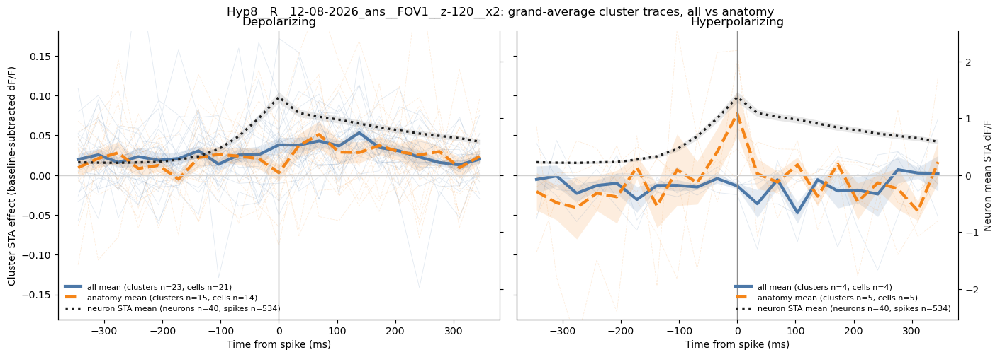

,result_type,n_clusters,n_cells,n_depolarizing,n_hyperpolarizing
0,all,27,25,23,4
1,anatomy,20,19,15,5


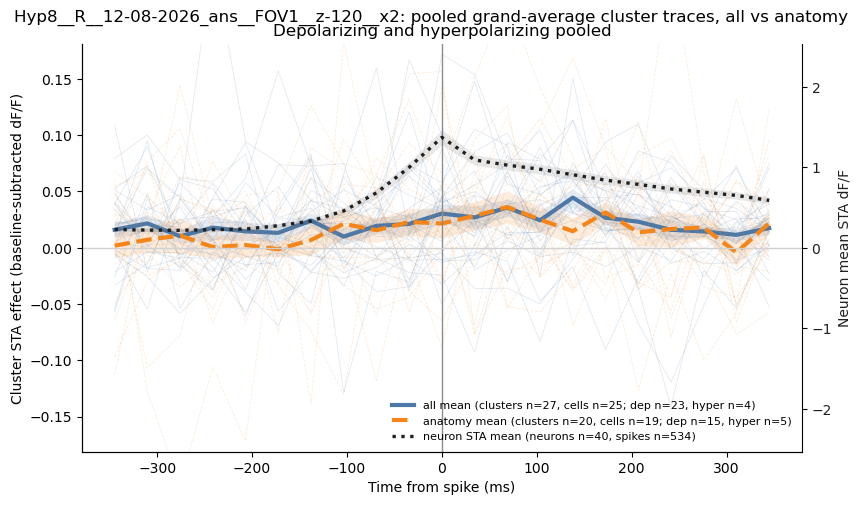

In [32]:
GRAND_AVERAGE_RESULT_TYPES = ["all", "anatomy"]
GRAND_AVERAGE_ONLY_SIGNIFICANT = True

grand_cluster_df = single_data.clusters[single_data.clusters["result_type"].isin(GRAND_AVERAGE_RESULT_TYPES)].copy()
if GRAND_AVERAGE_ONLY_SIGNIFICANT:
    grand_cluster_df = grand_cluster_df[grand_cluster_df["is_significant"]].copy()
if grand_cluster_df.empty:
    raise ValueError("No all/anatomy cluster traces are available for the selected significance filter.")

polarity_label = {"positive": "depolarizing", "negative": "hyperpolarizing"}
result_color = {"all": "#4C78A8", "anatomy": "#F58518"}
result_linestyle = {"all": "solid", "anatomy": "dashed"}
sign_order = ["positive", "negative"]

grand_rows = []
for (result_type, sign), group in grand_cluster_df.groupby(["result_type", "sign"], sort=True):
    traces = [np.asarray(t, dtype=float) for t in group["mean_trace"] if np.asarray(t).size]
    t_rels = [np.asarray(t, dtype=int) for t in group["t_rel"] if np.asarray(t).size]
    if not traces or not t_rels:
        continue
    min_len = min([t.size for t in traces] + [tr.size for tr in t_rels])
    arr = np.vstack([t[:min_len] for t in traces])
    t_rel = t_rels[0][:min_len]
    grand_rows.append({
        "result_type": str(result_type),
        "sign": str(sign).lower(),
        "t_rel": t_rel,
        "x_ms": t_rel.astype(np.float32) * (1000.0 / float(ctx.fps)),
        "traces": arr,
        "mean": np.nanmean(arr, axis=0),
        "sem": np.nanstd(arr, axis=0) / np.sqrt(max(1, arr.shape[0])),
        "n_clusters": int(arr.shape[0]),
        "n_cells": int(group["cell_id"].nunique()),
    })

grand_summary = pd.DataFrame([
    {
        "result_type": row["result_type"],
        "sign": polarity_label.get(row["sign"], row["sign"]),
        "n_clusters": row["n_clusters"],
        "n_cells": row["n_cells"],
    }
    for row in grand_rows
]).sort_values(["sign", "result_type"])
display(grand_summary)

finite_values = []
for row in grand_rows:
    vals = np.asarray(row["traces"], dtype=float).ravel()
    vals = vals[np.isfinite(vals)]
    if vals.size:
        finite_values.append(vals)
y_radius = max(float(np.nanpercentile(np.abs(np.concatenate(finite_values)), 99)), 1e-6) * 1.15 if finite_values else 1.0

def _compute_confirmed_neuron_sta(t_rel):
    if "confirmed_peaks_df" not in globals():
        raise ValueError("Run section 5 first so confirmed_peaks_df is available.")
    if "F" not in globals():
        F_local = np.asarray(ctx.suite2p_ctx["F"], dtype=np.float32)
    else:
        F_local = np.asarray(F, dtype=np.float32)
    t_rel = np.asarray(t_rel, dtype=int)
    neuron_sta_traces = []
    n_used_spikes = 0
    for peak_row in confirmed_peaks_df.itertuples():
        cell_id = int(peak_row.cell_id)
        if cell_id < 0 or cell_id >= F_local.shape[0]:
            continue
        trace = robust_dff(F_local[cell_id])
        peaks = np.asarray(peak_row.all_peaks, dtype=np.int32)
        peaks = peaks[(peaks >= 0) & (peaks < F_local.shape[1])]
        segments = []
        for peak in peaks:
            idx = peak + t_rel
            if np.all((idx >= 0) & (idx < trace.size)):
                segments.append(trace[idx])
        if segments:
            neuron_sta_traces.append(np.nanmean(np.vstack(segments), axis=0))
            n_used_spikes += len(segments)
    if not neuron_sta_traces:
        return None
    arr = np.vstack(neuron_sta_traces)
    return {
        "t_rel": t_rel,
        "x_ms": t_rel.astype(np.float32) * (1000.0 / float(ctx.fps)),
        "traces": arr,
        "mean": np.nanmean(arr, axis=0),
        "sem": np.nanstd(arr, axis=0) / np.sqrt(max(1, arr.shape[0])),
        "n_neurons": int(arr.shape[0]),
        "n_spikes": int(n_used_spikes),
    }

def _overlay_neuron_sta(ax, neuron_sta, label_prefix="neuron STA"):
    if neuron_sta is None:
        return None
    ax_neuron = ax.twinx()
    x = neuron_sta["x_ms"]
    mean = neuron_sta["mean"]
    sem = neuron_sta["sem"]
    ax_neuron.plot(
        x,
        mean,
        color="0.12",
        linestyle=":",
        linewidth=2.4,
        label=f"{label_prefix} mean (neurons n={neuron_sta['n_neurons']}, spikes n={neuron_sta['n_spikes']})",
    )
    ax_neuron.fill_between(x, mean - sem, mean + sem, color="0.12", alpha=0.10, linewidth=0)
    finite = np.asarray(neuron_sta["traces"], dtype=float).ravel()
    finite = finite[np.isfinite(finite)]
    neuron_y_radius = max(float(np.nanpercentile(np.abs(finite), 99)), 1e-6) * 1.15 if finite.size else 1.0
    ax_neuron.set_ylim(-neuron_y_radius, neuron_y_radius)
    ax_neuron.set_ylabel("Neuron mean STA dF/F", color="0.12")
    ax_neuron.tick_params(axis="y", labelcolor="0.12")
    ax_neuron.spines["top"].set_visible(False)
    return ax_neuron

neuron_sta = _compute_confirmed_neuron_sta(grand_rows[0]["t_rel"]) if grand_rows else None
if neuron_sta is not None:
    display(pd.DataFrame([{
        "trace_type": "confirmed neuron mean STA",
        "n_neurons": neuron_sta["n_neurons"],
        "n_spikes": neuron_sta["n_spikes"],
    }]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True, constrained_layout=True)
separated_neuron_axes = []
for ax, sign in zip(axes, sign_order):
    rows_for_sign = [row for row in grand_rows if row["sign"] == sign]
    if not rows_for_sign:
        ax.text(0.5, 0.5, f"No {polarity_label.get(sign, sign)} clusters", transform=ax.transAxes, ha="center", va="center")
    for row in sorted(rows_for_sign, key=lambda r: GRAND_AVERAGE_RESULT_TYPES.index(r["result_type"])):
        color = result_color.get(row["result_type"], "0.4")
        linestyle = result_linestyle.get(row["result_type"], "solid")
        for trace in row["traces"]:
            ax.plot(row["x_ms"], trace, color=color, linestyle=linestyle, linewidth=0.6, alpha=0.16)
        ax.plot(
            row["x_ms"],
            row["mean"],
            color=color,
            linestyle=linestyle,
            linewidth=3.0,
            label=f"{row['result_type']} mean (clusters n={row['n_clusters']}, cells n={row['n_cells']})",
        )
        ax.fill_between(row["x_ms"], row["mean"] - row["sem"], row["mean"] + row["sem"], color=color, alpha=0.14, linewidth=0)
    ax.axvline(0, color="0.55", linewidth=1)
    ax.axhline(0, color="0.82", linewidth=1)
    ax.set_title(polarity_label.get(sign, sign).title())
    ax.set_xlabel("Time from spike (ms)")
    ax.set_ylim(-y_radius, y_radius)
    ax.spines[["top", "right"]].set_visible(False)
    ax_neuron = _overlay_neuron_sta(ax, neuron_sta)
    separated_neuron_axes.append(ax_neuron)
    handles, labels = ax.get_legend_handles_labels()
    if ax_neuron is not None:
        neuron_handles, neuron_labels = ax_neuron.get_legend_handles_labels()
        handles += neuron_handles
        labels += neuron_labels
    ax.legend(handles, labels, frameon=False, fontsize=8, loc="best")
if separated_neuron_axes and separated_neuron_axes[0] is not None:
    separated_neuron_axes[0].set_ylabel("")
    separated_neuron_axes[0].tick_params(axis="y", labelright=False)
axes[0].set_ylabel("Cluster STA effect (baseline-subtracted dF/F)")
fig.suptitle(f"{ctx.canonical_id}: grand-average cluster traces, all vs anatomy", y=1.02)
plt.show()

# Same comparison with depolarizing and hyperpolarizing clusters pooled together.
pooled_rows = []
for result_type, group in grand_cluster_df.groupby("result_type", sort=True):
    traces = [np.asarray(t, dtype=float) for t in group["mean_trace"] if np.asarray(t).size]
    t_rels = [np.asarray(t, dtype=int) for t in group["t_rel"] if np.asarray(t).size]
    if not traces or not t_rels:
        continue
    min_len = min([t.size for t in traces] + [tr.size for tr in t_rels])
    arr = np.vstack([t[:min_len] for t in traces])
    t_rel = t_rels[0][:min_len]
    pooled_rows.append({
        "result_type": str(result_type),
        "t_rel": t_rel,
        "x_ms": t_rel.astype(np.float32) * (1000.0 / float(ctx.fps)),
        "traces": arr,
        "mean": np.nanmean(arr, axis=0),
        "sem": np.nanstd(arr, axis=0) / np.sqrt(max(1, arr.shape[0])),
        "n_clusters": int(arr.shape[0]),
        "n_cells": int(group["cell_id"].nunique()),
        "n_depolarizing": int((group["sign"].astype(str).str.lower() == "positive").sum()),
        "n_hyperpolarizing": int((group["sign"].astype(str).str.lower() == "negative").sum()),
    })

pooled_summary = pd.DataFrame([
    {
        "result_type": row["result_type"],
        "n_clusters": row["n_clusters"],
        "n_cells": row["n_cells"],
        "n_depolarizing": row["n_depolarizing"],
        "n_hyperpolarizing": row["n_hyperpolarizing"],
    }
    for row in pooled_rows
]).sort_values("result_type")
display(pooled_summary)

pooled_finite_values = []
for row in pooled_rows:
    vals = np.asarray(row["traces"], dtype=float).ravel()
    vals = vals[np.isfinite(vals)]
    if vals.size:
        pooled_finite_values.append(vals)
pooled_y_radius = max(float(np.nanpercentile(np.abs(np.concatenate(pooled_finite_values)), 99)), 1e-6) * 1.15 if pooled_finite_values else 1.0

fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
for row in sorted(pooled_rows, key=lambda r: GRAND_AVERAGE_RESULT_TYPES.index(r["result_type"])):
    color = result_color.get(row["result_type"], "0.4")
    linestyle = result_linestyle.get(row["result_type"], "solid")
    for trace in row["traces"]:
        ax.plot(row["x_ms"], trace, color=color, linestyle=linestyle, linewidth=0.6, alpha=0.16)
    ax.plot(
        row["x_ms"],
        row["mean"],
        color=color,
        linestyle=linestyle,
        linewidth=3.0,
        label=(
            f"{row['result_type']} mean "
            f"(clusters n={row['n_clusters']}, cells n={row['n_cells']}; "
            f"dep n={row['n_depolarizing']}, hyper n={row['n_hyperpolarizing']})"
        ),
    )
    ax.fill_between(row["x_ms"], row["mean"] - row["sem"], row["mean"] + row["sem"], color=color, alpha=0.14, linewidth=0)
ax.axvline(0, color="0.55", linewidth=1)
ax.axhline(0, color="0.82", linewidth=1)
ax.set_xlabel("Time from spike (ms)")
ax.set_ylabel("Cluster STA effect (baseline-subtracted dF/F)")
ax.set_ylim(-pooled_y_radius, pooled_y_radius)
ax.set_title("Depolarizing and hyperpolarizing pooled")
ax.spines[["top", "right"]].set_visible(False)
ax_neuron = _overlay_neuron_sta(ax, neuron_sta)
handles, labels = ax.get_legend_handles_labels()
if ax_neuron is not None:
    neuron_handles, neuron_labels = ax_neuron.get_legend_handles_labels()
    handles += neuron_handles
    labels += neuron_labels
ax.legend(handles, labels, frameon=False, fontsize=8, loc="best")
fig.suptitle(f"{ctx.canonical_id}: pooled grand-average cluster traces, all vs anatomy", y=1.02)
plt.show()